# Smart Inventory — Time-Series Baselines

This notebook evaluates classical forecasting approaches before we compare them with machine-learning models.

## Models
1. Naive Forecast
2. Seasonal Naive (7-day)
3. Holt-Winters / Exponential Smoothing
4. SARIMAX

## Important
- The dataset contains 100 Store + Product time series.
- We use the **same chronological test period** for evaluation.
- No future observations are used to train a model.
- `Units Sold` is the target.
- `Demand Forecast` is not used because it causes target leakage.

> SARIMAX can be computationally expensive when fitting 100 separate series. The notebook therefore includes a configurable `MAX_SERIES` setting so we can first test the pipeline on a smaller number of series and then scale it up.

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Configuration

In [2]:
# Number of Store-Product series to evaluate.
# Set to None to run all 100 series.
MAX_SERIES = 10

# Forecast horizon is the entire test period.
# The split uses approximately 70% train, 15% validation, 15% test dates.
TRAIN_RATIO = 0.70
VALIDATION_RATIO = 0.15

# Seasonal period for daily retail demand.
# 7 represents a weekly pattern.
SEASONAL_PERIOD = 7

## 2. Load and prepare the original dataset

In [3]:
df = pd.read_csv("../DATA/retail_store_inventory.csv")

df["Date"] = pd.to_datetime(df["Date"])

df = df.sort_values(
    ["Store ID", "Product ID", "Date"]
).reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Date range:", df["Date"].min(), "→", df["Date"].max())
print("Store-Product combinations:", df[["Store ID", "Product ID"]].drop_duplicates().shape[0])

Dataset shape: (73100, 15)
Date range: 2022-01-01 00:00:00 → 2024-01-01 00:00:00
Store-Product combinations: 100


## 3. Create chronological train / validation / test dates

In [4]:
unique_dates = np.sort(df["Date"].unique())

n_dates = len(unique_dates)

train_end_idx = int(n_dates * TRAIN_RATIO)
validation_end_idx = int(n_dates * (TRAIN_RATIO + VALIDATION_RATIO))

train_end_date = unique_dates[train_end_idx - 1]
validation_end_date = unique_dates[validation_end_idx - 1]

print("Training:", unique_dates[0], "→", train_end_date)
print("Validation:", unique_dates[train_end_idx], "→", validation_end_date)
print("Test:", unique_dates[validation_end_idx], "→", unique_dates[-1])

Training: 2022-01-01T00:00:00.000000 → 2023-05-26T00:00:00.000000
Validation: 2023-05-27T00:00:00.000000 → 2023-09-13T00:00:00.000000
Test: 2023-09-14T00:00:00.000000 → 2024-01-01T00:00:00.000000


## 4. Create a series-level evaluation dataset

For the baselines below, each Store + Product combination is treated as an individual daily demand series.

In [5]:
series_keys = (
    df[["Store ID", "Product ID"]]
    .drop_duplicates()
    .sort_values(["Store ID", "Product ID"])
    .reset_index(drop=True)
)

if MAX_SERIES is not None:
    series_keys = series_keys.head(MAX_SERIES)

print("Series to evaluate:", len(series_keys))
series_keys.head()

Series to evaluate: 10


,Store ID,Product ID
0,S001,P0001
1,S001,P0002
2,S001,P0003
3,S001,P0004
4,S001,P0005


## 5. Helper function for evaluation

In [6]:
def evaluate_forecast(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

print("Evaluation function ready.")

Evaluation function ready.


## 6. Naive Forecast

The naive model predicts:

**Tomorrow's demand = today's demand**

For the test period, the first prediction uses the final training observation. Later predictions use the actual previous day's demand.

This is a very important benchmark.

In [7]:
naive_results = []

for _, key in series_keys.iterrows():
    store = key["Store ID"]
    product = key["Product ID"]

    series = df[
        (df["Store ID"] == store) &
        (df["Product ID"] == product)
    ].sort_values("Date")

    train = series[series["Date"] <= train_end_date]
    test = series[series["Date"] > validation_end_date]

    if len(train) == 0 or len(test) == 0:
        continue

    # Previous observed value for each test date.
    combined = pd.concat([train, test])
    test_predictions = combined["Units Sold"].shift(1).loc[test.index]

    metrics = evaluate_forecast(
        test["Units Sold"],
        test_predictions
    )

    metrics.update({
        "Store ID": store,
        "Product ID": product
    })

    naive_results.append(metrics)

naive_results = pd.DataFrame(naive_results)

print(naive_results.head())
print("\nAverage Naive performance:")
print(naive_results[["MAE", "RMSE", "R2"]].mean())

          MAE        RMSE        R2 Store ID Product ID
0  118.627273  154.576695 -1.031319     S001      P0001
1  103.345455  140.136103 -0.918379     S001      P0002
2  120.963636  154.434629 -0.941546     S001      P0003
3  124.554545  155.419930 -0.887870     S001      P0004
4  123.654545  163.195532 -1.280862     S001      P0005

Average Naive performance:
MAE     118.010000
RMSE    151.317400
R2       -0.988353
dtype: float64


## 7. Seasonal Naive Forecast

For daily retail data, a 7-day seasonal baseline is useful:

**Today's forecast = demand 7 days ago**

This tests whether weekly demand patterns are useful.

In [8]:
seasonal_naive_results = []

for _, key in series_keys.iterrows():
    store = key["Store ID"]
    product = key["Product ID"]

    series = df[
        (df["Store ID"] == store) &
        (df["Product ID"] == product)
    ].sort_values("Date")

    train = series[series["Date"] <= train_end_date]
    test = series[series["Date"] > validation_end_date]

    if len(train) < SEASONAL_PERIOD or len(test) == 0:
        continue

    combined = pd.concat([train, test])

    test_predictions = (
        combined["Units Sold"]
        .shift(SEASONAL_PERIOD)
        .loc[test.index]
    )

    valid = test_predictions.notna()

    metrics = evaluate_forecast(
        test.loc[valid, "Units Sold"],
        test_predictions.loc[valid]
    )

    metrics.update({
        "Store ID": store,
        "Product ID": product
    })

    seasonal_naive_results.append(metrics)

seasonal_naive_results = pd.DataFrame(seasonal_naive_results)

print(seasonal_naive_results.head())
print("\nAverage Seasonal Naive performance:")
print(seasonal_naive_results[["MAE", "RMSE", "R2"]].mean())

          MAE        RMSE        R2 Store ID Product ID
0  117.554545  151.227673 -0.944252     S001      P0001
1  107.709091  139.229895 -0.893649     S001      P0002
2  130.163636  161.947747 -1.135050     S001      P0003
3  131.709091  164.601778 -1.117520     S001      P0004
4  113.854545  150.469206 -0.938999     S001      P0005

Average Seasonal Naive performance:
MAE     116.335455
RMSE    148.880580
R2       -0.917885
dtype: float64


## 8. Holt-Winters / Exponential Smoothing

Holt-Winters can model level, trend and seasonality.

Because our data is daily and we are testing weekly seasonality, the seasonal period is 7.

In [9]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

holt_results = []

for _, key in series_keys.iterrows():
    store = key["Store ID"]
    product = key["Product ID"]

    series = df[
        (df["Store ID"] == store) &
        (df["Product ID"] == product)
    ].sort_values("Date")

    train = series[series["Date"] <= train_end_date]
    test = series[series["Date"] > validation_end_date]

    if len(train) < 2 * SEASONAL_PERIOD or len(test) == 0:
        continue

    y_train = train["Units Sold"].astype(float).values
    y_test = test["Units Sold"].astype(float).values

    try:
        model = ExponentialSmoothing(
            y_train,
            trend="add",
            seasonal="add",
            seasonal_periods=SEASONAL_PERIOD,
            initialization_method="estimated"
        )

        fitted_model = model.fit(optimized=True)

        predictions = fitted_model.forecast(len(y_test))

        metrics = evaluate_forecast(
            y_test,
            predictions
        )

        metrics.update({
            "Store ID": store,
            "Product ID": product
        })

        holt_results.append(metrics)

    except Exception as e:
        print(f"Skipped {store}-{product}: {e}")

holt_results = pd.DataFrame(holt_results)

print(holt_results.head())

if len(holt_results):
    print("\nAverage Holt-Winters performance:")
    print(holt_results[["MAE", "RMSE", "R2"]].mean())

         MAE        RMSE        R2 Store ID Product ID
0  89.458308  107.740615  0.013155     S001      P0001
1  83.552601  103.397711 -0.044375     S001      P0002
2  97.331649  112.736570 -0.034637     S001      P0003
3  98.294128  114.965257 -0.032980     S001      P0004
4  86.494064  106.984182  0.019785     S001      P0005

Average Holt-Winters performance:
MAE      89.642616
RMSE    108.527192
R2       -0.018501
dtype: float64


## 9. SARIMAX

SARIMAX is a seasonal ARIMA model that can also use external variables.

For the first experiment, we use the historical demand itself and weekly seasonality.

**Note:** Fitting SARIMAX separately for every Store + Product combination can be slow. Start with `MAX_SERIES = 10`. If the pipeline works, increase it gradually.

In [10]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarimax_results = []

for _, key in series_keys.iterrows():
    store = key["Store ID"]
    product = key["Product ID"]

    series = df[
        (df["Store ID"] == store) &
        (df["Product ID"] == product)
    ].sort_values("Date")

    train = series[series["Date"] <= train_end_date]
    test = series[series["Date"] > validation_end_date]

    if len(train) < 60 or len(test) == 0:
        continue

    y_train = train["Units Sold"].astype(float).values
    y_test = test["Units Sold"].astype(float).values

    try:
        model = SARIMAX(
            y_train,
            order=(1, 1, 1),
            seasonal_order=(1, 1, 1, SEASONAL_PERIOD),
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        fitted_model = model.fit(
            disp=False
        )

        predictions = fitted_model.forecast(
            steps=len(y_test)
        )

        metrics = evaluate_forecast(
            y_test,
            predictions
        )

        metrics.update({
            "Store ID": store,
            "Product ID": product
        })

        sarimax_results.append(metrics)

    except Exception as e:
        print(f"Skipped {store}-{product}: {e}")

sarimax_results = pd.DataFrame(sarimax_results)

print(sarimax_results.head())

if len(sarimax_results):
    print("\nAverage SARIMAX performance:")
    print(sarimax_results[["MAE", "RMSE", "R2"]].mean())

         MAE        RMSE        R2 Store ID Product ID
0  89.210631  107.759750  0.012805     S001      P0001
1  82.291557  104.444967 -0.065637     S001      P0002
2  97.506694  112.842042 -0.036574     S001      P0003
3  98.118761  114.959285 -0.032872     S001      P0004
4  86.381692  107.103316  0.017600     S001      P0005

Average SARIMAX performance:
MAE      89.382063
RMSE    108.788214
R2       -0.023489
dtype: float64


## 10. Compare the models

In [11]:
summary_rows = []

def add_summary(name, result_df):
    if result_df is not None and len(result_df):
        values = result_df[["MAE", "RMSE", "R2"]].mean()
        summary_rows.append({
            "Model": name,
            "MAE": values["MAE"],
            "RMSE": values["RMSE"],
            "R2": values["R2"]
        })

add_summary("Naive", naive_results)
add_summary("Seasonal Naive", seasonal_naive_results)
add_summary("Holt-Winters", holt_results)
add_summary("SARIMAX", sarimax_results)

model_comparison = pd.DataFrame(summary_rows).sort_values("MAE")

model_comparison

,Model,MAE,RMSE,R2
3,SARIMAX,89.382063,108.788214,-0.023489
2,Holt-Winters,89.642616,108.527192,-0.018501
1,Seasonal Naive,116.335455,148.880580,-0.917885
0,Naive,118.010000,151.317400,-0.988353


## 11. Visualize model comparison

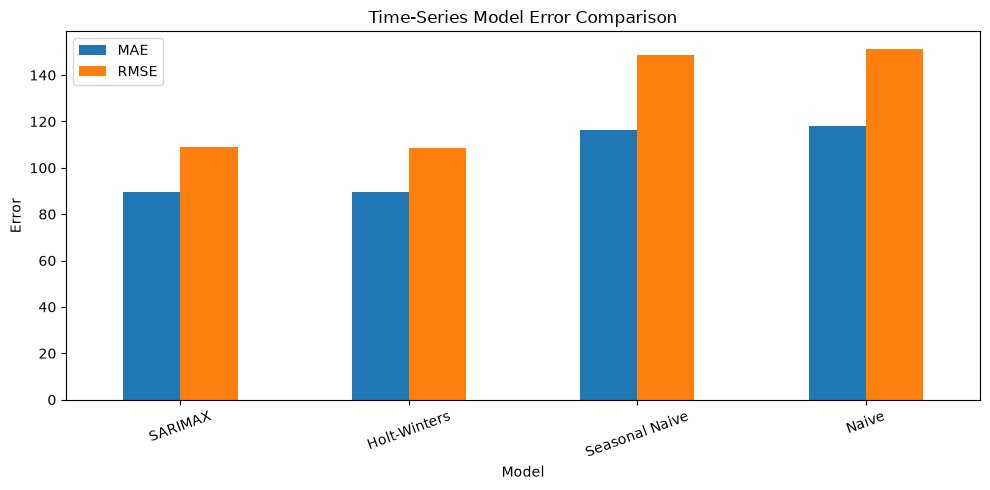

In [14]:
if len(model_comparison):
    model_comparison.plot(
        x="Model",
        y=["MAE", "RMSE"],
        kind="bar",
        figsize=(10, 5)
    )

    plt.title("Time-Series Model Error Comparison")
    plt.ylabel("Error")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

## 12. Inspect one Store + Product forecast

This gives us a visual sanity check rather than relying only on aggregate metrics.

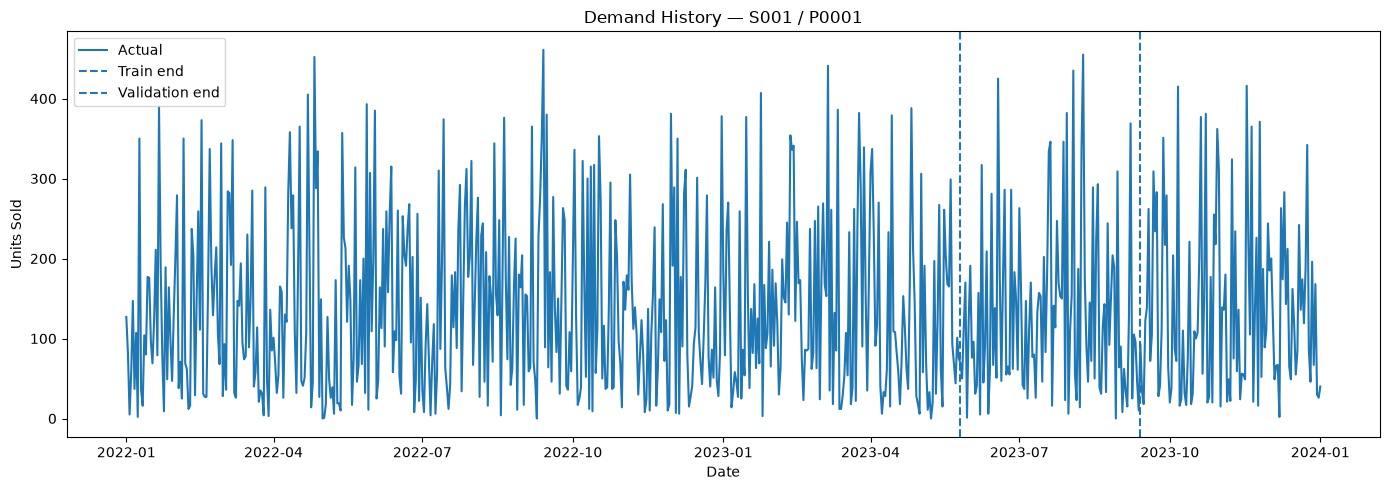

In [15]:
import matplotlib.pyplot as plt

sample_store = series_keys.iloc[0]["Store ID"]
sample_product = series_keys.iloc[0]["Product ID"]

sample = df[
    (df["Store ID"] == sample_store) &
    (df["Product ID"] == sample_product)
].sort_values("Date")

plt.figure(figsize=(14, 5))
plt.plot(sample["Date"], sample["Units Sold"], label="Actual")
plt.axvline(train_end_date, linestyle="--", label="Train end")
plt.axvline(validation_end_date, linestyle="--", label="Validation end")
plt.title(f"Demand History — {sample_store} / {sample_product}")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.tight_layout()
plt.show()

# Conclusion

This notebook establishes classical forecasting benchmarks.

### What we learned
- Naive forecasting gives a minimum baseline.
- Seasonal Naive tests whether weekly seasonality helps.
- Holt-Winters models level, trend and seasonality.
- SARIMAX models autoregressive and seasonal structure.

### Next step

Compare these results against the ML models:

- Random Forest
- XGBoost
- LightGBM
- CatBoost

The final model should be selected based on performance on unseen future data, especially **MAE and RMSE**.

> The SARIMAX implementation here is a baseline. We can later add exogenous variables such as price, discount and promotions if SARIMAX performs competitively.